## importing libraries and loading prepared data

In [1]:
## importing libraries and loading prepared data
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

FILE_DIR = Path.cwd() / "Data_Collection"
ELIGIBLE_PATH = FILE_DIR / "eligible_model_data.csv"
METADATA_PATH = FILE_DIR / "feature_metadata.json"
VALIDATION_PATH = FILE_DIR / "validation_model_comparison.csv"

for required_path in (ELIGIBLE_PATH, METADATA_PATH, VALIDATION_PATH):
    if not required_path.exists():
        raise FileNotFoundError(
            f"Required file not found: {required_path}. "
            "Run 03_Feature_Selection_and_Model_Selection.ipynb first."
        )

eligible_data = pd.read_csv(ELIGIBLE_PATH)
with open(METADATA_PATH, "r", encoding="utf-8") as f:
    feature_metadata = json.load(f)
validation_results_df = pd.read_csv(VALIDATION_PATH)

numeric_features = feature_metadata["numeric_features"]
categorical_features = feature_metadata.get("categorical_features", [])
target_col = feature_metadata["target"]
feature_cols = numeric_features + categorical_features
selected_model_name = feature_metadata.get(
    "validation_winner",
    feature_metadata.get("deployment_candidate")
)

required_cols = set(feature_cols + [target_col, "Year", "Area", "Item"])
missing_cols = required_cols - set(eligible_data.columns)
if missing_cols:
    raise ValueError(f"Required columns are missing: {sorted(missing_cols)}")

eligible_data["Year"] = eligible_data["Year"].astype(int)
print("Selected by validation:", selected_model_name)
print("Eligible rows:", len(eligible_data))
print("Model features:", feature_cols)

Selected by validation: Ridge Regression (lags only)
Eligible rows: 23189
Model features: ['Yield_lag_1', 'Yield_lag_2', 'Yield_lag_3', 'Yield_rolling_mean_3', 'Area', 'Item']


## recreating the chronological training and test sets

In [2]:
## recreating the chronological training and test sets
train_eval = eligible_data.loc[eligible_data["Year"] <= 2013].copy()
test_eval = eligible_data.loc[eligible_data["Year"].between(2019, 2023)].copy()

if train_eval.empty or test_eval.empty:
    raise ValueError("Training or test split is empty. Check the available years.")

X_train_all = train_eval[feature_cols]
y_train_all = train_eval[target_col]
X_test_all = test_eval[feature_cols]
y_test = test_eval[target_col]

print(f"Training rows: {len(train_eval)} | years: {train_eval['Year'].min()}–{train_eval['Year'].max()}")
print(f"Held-out test rows: {len(test_eval)} | years: {test_eval['Year'].min()}–{test_eval['Year'].max()}")

Training rows: 19036 | years: 1964–2013
Held-out test rows: 2084 | years: 2019–2023


## defining candidate model pipelines

In [3]:
## defining candidate model pipelines
def make_numeric_pipeline(model, scale=False):
    steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        steps.append(("scaler", StandardScaler()))
    steps.append(("model", model))
    return Pipeline(steps=steps)

def make_categorical_pipeline(model):
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", SimpleImputer(strategy="median"), numeric_features),
            ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
        ],
        remainder="drop"
    )
    return Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

def build_candidate(name):
    if name == "Linear Regression (lags only)":
        return make_numeric_pipeline(LinearRegression(), scale=True), numeric_features
    if name == "Ridge Regression (lags only)":
        return make_numeric_pipeline(Ridge(alpha=1.0), scale=True), numeric_features
    if name == "Decision Tree (lags only)":
        return make_numeric_pipeline(
            DecisionTreeRegressor(max_depth=12, min_samples_leaf=5, random_state=42)
        ), numeric_features
    if name == "Random Forest (lags only)":
        return make_numeric_pipeline(
            RandomForestRegressor(
                n_estimators=200, max_depth=12, min_samples_leaf=3,
                random_state=42, n_jobs=-1
            )
        ), numeric_features
    if name == "Random Forest + Area + Crop":
        return make_categorical_pipeline(
            RandomForestRegressor(
                n_estimators=200, max_depth=12, min_samples_leaf=3,
                random_state=42, n_jobs=-1
            )
        ), feature_cols
    if name == "Gradient Boosting + Area + Crop":
        return make_categorical_pipeline(
            GradientBoostingRegressor(
                n_estimators=150, learning_rate=0.05, max_depth=3,
                loss="squared_error", random_state=42
            )
        ), feature_cols
    if name == "XGBoost (lags only)":
        from xgboost import XGBRegressor
        return make_numeric_pipeline(
            XGBRegressor(
                n_estimators=300, max_depth=6, learning_rate=0.05,
                subsample=0.8, colsample_bytree=1.0,
                objective="reg:squarederror", random_state=42, n_jobs=-1
            )
        ), numeric_features
    raise ValueError(f"Unsupported selected model: {name}")

## fitting the selected model on training data

In [4]:
## fitting the selected model on training data
if selected_model_name == "Previous-Year Baseline":
    raise ValueError(
        "The validation winner is the baseline, which is not a fitted ML pipeline. "
        "Review model selection before creating a deployment model."
    )

try:
    evaluation_model, evaluation_features = build_candidate(selected_model_name)
except ImportError as exc:
    raise ImportError(
        "The selected model requires an optional library that is not installed."
    ) from exc

evaluation_model.fit(
    X_train_all[evaluation_features],
    y_train_all
)
test_predictions = evaluation_model.predict(X_test_all[evaluation_features])

print("Fitted model:", selected_model_name)
print("Test predictions generated:", len(test_predictions))

Fitted model: Ridge Regression (lags only)
Test predictions generated: 2084


## evaluating the selected model against the previous-year baseline

In [5]:
## evaluating the selected model against the previous-year baseline
def metrics_row(name, actual, predicted):
    return {
        "Model": name,
        "MAE_kg_ha": mean_absolute_error(actual, predicted),
        "RMSE_kg_ha": float(np.sqrt(mean_squared_error(actual, predicted))),
        "R2": r2_score(actual, predicted)
    }

baseline_predictions = test_eval["Yield_lag_1"].to_numpy()
test_results = pd.DataFrame([
    metrics_row("Previous-Year Baseline", y_test, baseline_predictions),
    metrics_row(selected_model_name, y_test, test_predictions)
])

display(test_results.round(3))
test_results.to_csv(FILE_DIR / "final_test_model_comparison.csv", index=False)

,Model,MAE_kg_ha,RMSE_kg_ha,R2
0,Previous-Year Baseline,451.703,1238.276,0.856
1,Ridge Regression (lags only),429.002,1190.705,0.867


## analyzing model performance by crop

In [6]:
## analyzing model performance by crop
test_analysis = test_eval[["Area", "Item", "Year", target_col]].copy()
test_analysis = test_analysis.rename(columns={target_col: "Actual_Yield"})
test_analysis["Predicted_Yield"] = test_predictions
test_analysis["Error"] = test_analysis["Actual_Yield"] - test_analysis["Predicted_Yield"]
test_analysis["Absolute_Error"] = test_analysis["Error"].abs()

crop_metrics = []
for crop, group in test_analysis.groupby("Item"):
    actual = group["Actual_Yield"].to_numpy()
    predicted = group["Predicted_Yield"].to_numpy()
    crop_metrics.append({
        "Item": crop,
        "Observations": len(group),
        "MAE_kg_ha": mean_absolute_error(actual, predicted),
        "RMSE_kg_ha": float(np.sqrt(mean_squared_error(actual, predicted))),
        "R2": r2_score(actual, predicted)
    })

crop_metrics_df = pd.DataFrame(crop_metrics).set_index("Item")
display(crop_metrics_df.round(3))
crop_metrics_df.to_csv(FILE_DIR / "crop_wise_test_metrics.csv")

,Observations,MAE_kg_ha,RMSE_kg_ha,R2
Item,,,,
Maize (corn),838,586.923,1749.162,0.834
Rice,610,274.329,482.194,0.955
Wheat,636,369.273,625.580,0.912


## plotting actual versus predicted yield

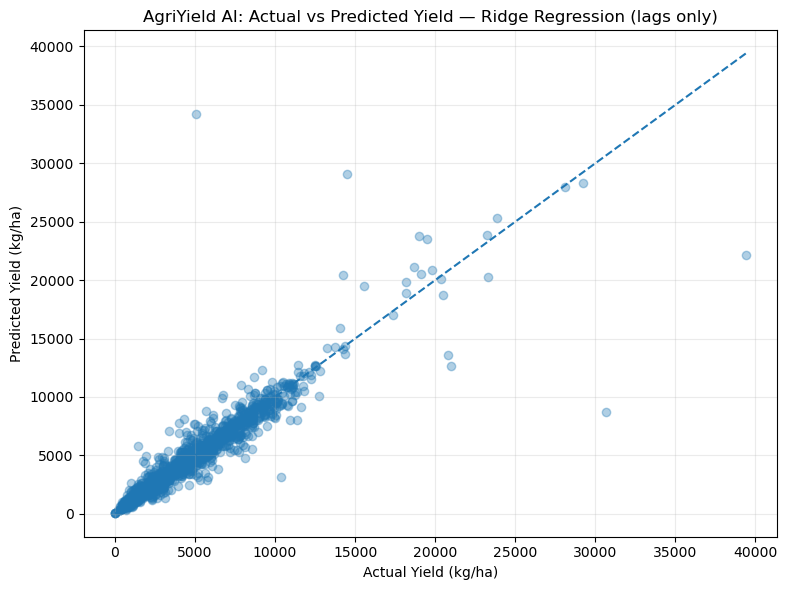

In [7]:
## plotting actual versus predicted yield
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(test_analysis["Actual_Yield"], test_analysis["Predicted_Yield"], alpha=0.35)

lower = min(test_analysis["Actual_Yield"].min(), test_analysis["Predicted_Yield"].min())
upper = max(test_analysis["Actual_Yield"].max(), test_analysis["Predicted_Yield"].max())
ax.plot([lower, upper], [lower, upper], linestyle="--")

ax.set_xlabel("Actual Yield (kg/ha)")
ax.set_ylabel("Predicted Yield (kg/ha)")
ax.set_title(f"AgriYield AI: Actual vs Predicted Yield — {selected_model_name}")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## reviewing the largest test prediction errors

In [8]:
## reviewing the largest test prediction errors
display(
    test_analysis.nlargest(15, "Absolute_Error")[
        ["Area", "Item", "Year", "Actual_Yield", "Predicted_Yield", "Error"]
    ].round(2)
)

,Area,Item,Year,Actual_Yield,Predicted_Yield,Error
19853,Oman,Maize (corn),2023,5052.0,34187.90,-29135.90
19851,Oman,Maize (corn),2021,30691.0,8712.71,21978.29
19852,Oman,Maize (corn),2022,39405.7,22124.08,17281.62
16984,Saint Vincent and the Grenadines,Maize (corn),2021,14472.7,29043.82,-14571.12
16206,Qatar,Maize (corn),2023,20979.2,12660.49,8318.71
10770,Kuwait,Wheat,2019,10363.6,3114.36,7249.24
10819,Kuwait,Maize (corn),2019,20766.5,13558.71,7207.79
16985,Saint Vincent and the Grenadines,Maize (corn),2022,14222.2,20447.73,-6225.53
20150,United Arab Emirates,Maize (corn),2020,18982.7,23816.15,-4833.45
21047,Uruguay,Maize (corn),2023,1415.1,5821.84,-4406.74


## retraining the selected pipeline on all eligible historical data

In [9]:
## retraining the selected pipeline on all eligible historical data
# The held-out test metrics above remain the final performance estimate.
# This refit uses all eligible rows only after model selection and test evaluation.
final_model, deployment_features = build_candidate(selected_model_name)
final_model.fit(
    eligible_data[deployment_features],
    eligible_data[target_col]
)

MODEL_PATH = FILE_DIR / "agriyield_model_pipeline.joblib"
joblib.dump(final_model, MODEL_PATH)

deployment_metadata = {
    "project": "AgriYield AI",
    "model_name": selected_model_name,
    "target": target_col,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "model_input_features": deployment_features,
    "train_year_max": 2013,
    "validation_years": [2014, 2018],
    "test_years": [2019, 2023],
    "selection_metric": "MAE_kg_ha",
    "validation_winner": selected_model_name,
    "test_metrics": test_results.to_dict(orient="records")
}

with open(FILE_DIR / "model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(deployment_metadata, f, indent=2)

print("Saved model:", MODEL_PATH)
print("Saved metadata:", FILE_DIR / "model_metadata.json")

Saved model: C:\Users\acer\capstone_Project\Agriculture_Yield_Prediction\Crop_Field_Prediction_Using_ML\Data_Collection\agriyield_model_pipeline.joblib
Saved metadata: C:\Users\acer\capstone_Project\Agriculture_Yield_Prediction\Crop_Field_Prediction_Using_ML\Data_Collection\model_metadata.json


## testing the saved model pipeline

In [10]:
## testing the saved model pipeline
loaded_model = joblib.load(MODEL_PATH)
sample_input = eligible_data[deployment_features].head(3)
sample_predictions = loaded_model.predict(sample_input)

print("Sample predictions (kg/ha):", np.round(sample_predictions, 2))
assert len(sample_predictions) == len(sample_input)
assert np.isfinite(sample_predictions).all()
print("Saved pipeline loaded and prediction smoke test passed.")

Sample predictions (kg/ha): [2041.95 2355.76 2401.26]
Saved pipeline loaded and prediction smoke test passed.
